# Make a basic neural network

## Dataset -> Iris Dataset

https://archive.ics.uci.edu/dataset/53/iris

In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [57]:
import matplotlib.pyplot as plt
import pandas as pd

# Import dataset

https://gist.github.com/netj/8836201

Raw Data URL: 
https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv

In [58]:
url = 'https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv'
my_df = pd.read_csv(url)

In [59]:
# 1. Display first 5 rows
print("First 5 Rows:\n", my_df.head())

# 2. Display last 5 rows
print("\nLast 5 Rows:\n", my_df.tail())

# 3. Dataset shape (rows, columns)
print("\nShape:", my_df.shape)

# 4. Number of rows and columns
print("\nRows:", my_df.shape[0])
print("Columns:", my_df.shape[1])

# 5. Column names
print("\nColumn Names:\n", my_df.columns.tolist())

# 6. Data types
print("\nData Types:\n", my_df.dtypes)

# 7. Dataset information
print("\nDataset Info:")
my_df.info()

# 8. Statistical summary
print("\nStatistical Summary:\n", my_df.describe())

# 9. Missing values
print("\nMissing Values:\n", my_df.isnull().sum())

# 10. Duplicate rows
print("\nDuplicate Rows:", my_df.duplicated().sum())

# 11. Total elements
print("\nTotal Elements:", my_df.size)

# 12. Memory usage
print("\nMemory Usage in bytes:")
print(my_df.memory_usage(deep=True))

First 5 Rows:
    sepal.length  sepal.width  petal.length  petal.width variety
0           5.1          3.5           1.4          0.2  Setosa
1           4.9          3.0           1.4          0.2  Setosa
2           4.7          3.2           1.3          0.2  Setosa
3           4.6          3.1           1.5          0.2  Setosa
4           5.0          3.6           1.4          0.2  Setosa

Last 5 Rows:
      sepal.length  sepal.width  petal.length  petal.width    variety
145           6.7          3.0           5.2          2.3  Virginica
146           6.3          2.5           5.0          1.9  Virginica
147           6.5          3.0           5.2          2.0  Virginica
148           6.2          3.4           5.4          2.3  Virginica
149           5.9          3.0           5.1          1.8  Virginica

Shape: (150, 5)

Rows: 150
Columns: 5

Column Names:
 ['sepal.length', 'sepal.width', 'petal.length', 'petal.width', 'variety']

Data Types:
 sepal.length    float64
sepal

In [60]:
my_df.variety.value_counts()

variety
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64

## Label encode all the categories 

In [61]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

my_df['variety'] = le.fit_transform(my_df['variety'])

print(my_df['variety'].value_counts())

variety
0    50
1    50
2    50
Name: count, dtype: int64


## Create a model class that inherit the nn.Module

In [62]:
class Model(nn.Module):

    # 1. INPUT LAYER: Takes 4 features of each flower as input
    #    (Sepal Length, Sepal Width, Petal Length, Petal Width)

    # 2. HIDDEN LAYER 1: Processes the 4 input features using a specified number of neurons

    # 3. HIDDEN LAYER 2: Further learns complex patterns from the previous hidden layer

    # 4. OUTPUT LAYER: Contains 3 neurons, representing the 3 flower classes
    #    (Setosa, Versicolor, Virginica)

    # In short -> Input -> H1 -> H2 -> Output


    def __init__(self, in_features = 4, h1 = 8, h2 = 9, out_features=3):
        super().__init__()
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)

        return x

    

In [63]:
# Create a manual seed
# NN on the ransomization

torch.manual_seed(41)

In [64]:
# create an instance of the model
model = Model()

# Train test split 

In [65]:
X = my_df.drop(["variety"], axis = 1)
y  = my_df["variety"]

In [66]:
# Convert these values into the numpy array

In [67]:
X = X.values
y = y.values

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=41)

In [70]:
# Since all the values in the X variable are in the decimal 
# Convert all the values into the float Tensor for the X
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

In [71]:
# ConvertY labels into the tensor but not float
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

# Critrea for the model eveluation
## Use cross entropy loss

In [72]:
criterion = nn.CrossEntropyLoss()

## Use Adam optimizer

Play with learning rate and epochs

If error does not go down in many iterations -> reduce the learning rate

In [175]:
optimizer_Adam = torch.optim.Adam(model.parameters(), lr = 0.01)

In [176]:
# What are the model parameters? 
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [177]:
# Example ---------------- DO NOT RUN ----------  ONLY FOR LEARNING RESNET

# import torch
# import torchvision.models as models

# model-Resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Train the model

In [178]:
epoch = 100
losses = []

optimizer_Adam.zero_grad()

for i in range(epoch):

    # Clear all previous gradients
    optimizer_Adam.zero_grad()
    # Forward pass
    y_pred = model.forward(X_train)

    # loss
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())

    # Gradients using backward propogation
    loss.backward()
    optimizer_Adam.step()
    
    print(f"Epoch {i+1}, Loss: {loss.item():.8f}")
    
    

Epoch 1, Loss: 0.00000007
Epoch 2, Loss: 0.63744396
Epoch 3, Loss: 0.00001261
Epoch 4, Loss: 0.08373739
Epoch 5, Loss: 0.05187763
Epoch 6, Loss: 0.00000011
Epoch 7, Loss: 0.00000424
Epoch 8, Loss: 0.06694972
Epoch 9, Loss: 0.04125294
Epoch 10, Loss: 0.00000244
Epoch 11, Loss: 0.00000000
Epoch 12, Loss: 0.00001565
Epoch 13, Loss: 0.01423315
Epoch 14, Loss: 0.03756642
Epoch 15, Loss: 0.00017777
Epoch 16, Loss: 0.00000033
Epoch 17, Loss: 0.00000000
Epoch 18, Loss: 0.00000011
Epoch 19, Loss: 0.00001596
Epoch 20, Loss: 0.00150644
Epoch 21, Loss: 0.02117824
Epoch 22, Loss: 0.00046701
Epoch 23, Loss: 0.00000618
Epoch 24, Loss: 0.00000012
Epoch 25, Loss: 0.00000000
Epoch 26, Loss: 0.00000000
Epoch 27, Loss: 0.00000005
Epoch 28, Loss: 0.00000058
Epoch 29, Loss: 0.00000580
Epoch 30, Loss: 0.00004688
Epoch 31, Loss: 0.00030337
Epoch 32, Loss: 0.00134375
Epoch 33, Loss: 0.00242612
Epoch 34, Loss: 0.00122579
Epoch 35, Loss: 0.00032011
Epoch 36, Loss: 0.00007558
Epoch 37, Loss: 0.00001921
Epoch 38, 

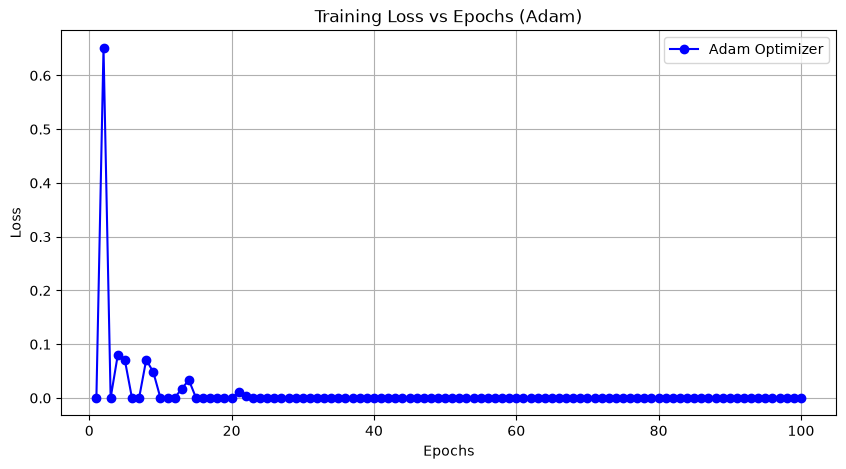

In [168]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(range(1, epoch+1), losses,
         color='blue',
         marker='o',
         label='Adam Optimizer')

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss vs Epochs (Adam)")

plt.legend()
plt.grid(True)
plt.show()

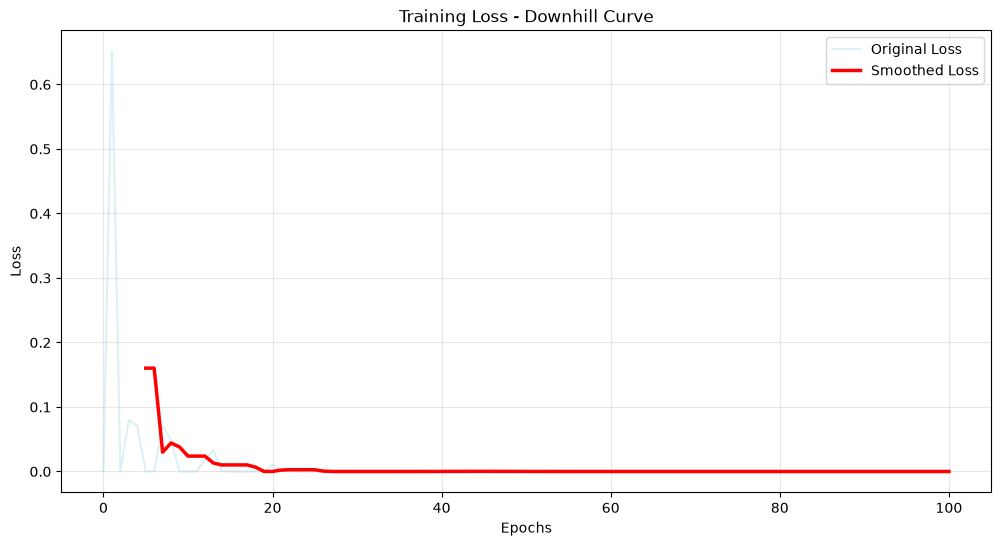

In [169]:
plt.figure(figsize=(12, 6))

plt.plot(losses, color='lightblue', alpha=0.4, label='Original Loss')

# Smooth the curve using moving average
window = 5

smooth_loss = np.convolve(
    losses,
    np.ones(window) / window,
    mode='valid'
)

plt.plot(
    range(window, len(losses) + 1),
    smooth_loss,
    color='red',
    linewidth=2.5,
    label='Smoothed Loss'
)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss - Downhill Curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [138]:
import numpy as np